## PageRank y HITS: Grafo

- Se define y justifica el grafo sobre el que corren PageRank y HITS (nodos, aristas, dirección y peso)

- Spark para las estadísticas del bipartito y scipy para componentes y comparaciones

### Constantes

`RANGO_PESO`: pesos de arista que se comparan

In [1]:
RANGO_PESO = ["binario", "n_adj", "log_monto", "monto"]

### Utilidades

In [2]:
NOTEBOOK = "a_grafo"
%run ../funciones.ipynb
%run funciones.ipynb

In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

`grafo_bipartito`: arista entidad → proveedor si hubo ≥ 1 adjudicación, con `n_adj` y `monto`

In [4]:
v_s = leer(artef_dir, "grafo_bipartito/vertices")
a_s = leer(artef_dir, "grafo_bipartito/aristas").cache()
print(f"vértices: {v_s.count():,} | aristas: {a_s.count():,}")

vértices: 89,009 | aristas: 136,099


---
### **1. Estructura del bipartito**

In [5]:
lado = lambda col: a_s.groupBy(F.col(col).alias("id")).agg(F.count("*").alias("grado"), F.sum("n_adj").alias("fuerza"),
                                                            F.sum("monto").alias("monto"))
grados = lado("src").unionByName(lado("dst")).join(v_s.select("id", "tipo"), "id").cache()
q = {t: grados.where(F.col("tipo") == t).approxQuantile("grado", [.5, .9, .99], .001) for t in ("entidad", "proveedor")}
n = dict(grados.groupBy("tipo").count().collect())
m = a_s.count()
resumen = pd.DataFrame([
    ("entidades", n["entidad"]), ("proveedores", n["proveedor"]), ("aristas", m),
    ("densidad (aristas / (E × P))", m / (n["entidad"] * n["proveedor"])),
    ("grado entidad p50", q["entidad"][0]), ("grado entidad p99", q["entidad"][2]),
    ("grado proveedor p50", q["proveedor"][0]), ("grado proveedor p99", q["proveedor"][2]),
    ("% proveedores con 1 entidad", 100 * grados.where("tipo = 'proveedor' AND grado = 1").count() / n["proveedor"]),
    ("% aristas con 1 adjudicación", 100 * a_s.where("n_adj = 1").count() / m)], columns=["medida", "valor"])
resumen

,medida,valor
0,entidades,2992.000000
1,proveedores,86017.000000
2,aristas,136099.000000
3,densidad (aristas / (E × P)),0.000529
4,grado entidad p50,19.000000
5,grado entidad p99,399.000000
6,grado proveedor p50,1.000000
7,grado proveedor p99,11.000000
8,% proveedores con 1 entidad,84.886708
9,% aristas con 1 adjudicación,79.789712


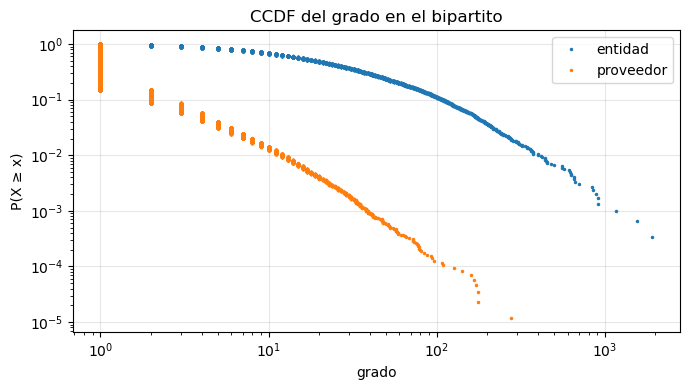

In [6]:
g = grados.select("tipo", "grado").toPandas()
fig, ax = plt.subplots(figsize=(7, 4))
for t, d in g.groupby("tipo"):
    x = np.sort(d.grado.to_numpy())
    ax.loglog(x, 1 - np.arange(len(x)) / len(x), ".", ms=3, label=t)
ax.set(xlabel="grado", ylabel="P(X ≥ x)", title="CCDF del grado en el bipartito"); ax.legend()
mostrar_fig("ccdf_grado")

- **Bipartito muy disperso:** 2,992 entidades × 86,017 proveedores con 136,099 aristas (densidad 0.053%)

- **84.9%** de los proveedores vende a una sola entidad

- La mediana de grado de un proveedor es 1 y la de una entidad 19

- **Cola pesada**: pocos actores concentran las relaciones, así que la centralidad discrimina

- **79.8%** de las aristas son de una sola adjudicación; `n_adj` separa relaciones recurrentes de esporádicas

---
### **2. Componentes conexas**

**Componente:** grupo de nodos unidos por algún camino de aristas

In [7]:
v, a, n_e = cargar_bipartito()
n_p = len(v) - n_e
M_bin = matriz_grafo(matriz_bip(a, n_e, n_p, "binario"), dirigido=False)
n_comp, comp = connected_components(M_bin, directed=False)
v["componente"] = comp
tam = v.groupby("componente").agg(nodos=("idx", "size"), entidades=("tipo", lambda t: int((t == "entidad").sum())))
gigante = tam.nodos.idxmax()
v["en_gigante"] = (v.componente == gigante).astype(int)
a["en_gigante"] = v.en_gigante.to_numpy()[a.i]
componentes = pd.DataFrame([
    ("componentes", n_comp),
    ("% nodos en la gigante", 100 * v.en_gigante.mean()),
    ("% entidades en la gigante", 100 * v.loc[v.tipo == "entidad", "en_gigante"].mean()),
    ("% aristas en la gigante", 100 * a.en_gigante.mean()),
    ("% monto en la gigante", 100 * a.loc[a.en_gigante == 1, "monto"].sum() / a.monto.sum()),
    ("tamaño mediano de las demás", tam.drop(gigante).nodos.median()),
    ("entidades fuera de la gigante", tam.drop(gigante).entidades.sum())], columns=["medida", "valor"])
componentes

,medida,valor
0,componentes,193.000000
1,% nodos en la gigante,99.007965
2,% entidades en la gigante,93.516043
3,% aristas en la gigante,99.492281
4,% monto en la gigante,99.729620
5,tamaño mediano de las demás,4.000000
6,entidades fuera de la gigante,194.000000


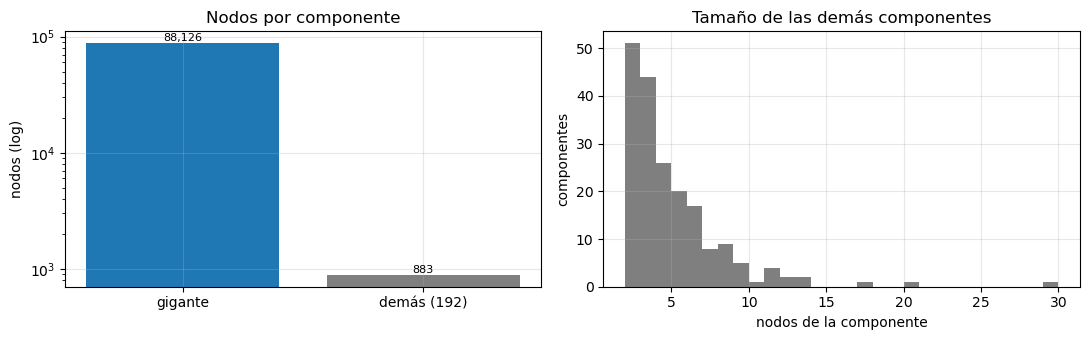

In [8]:
otras = tam.drop(gigante)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(["gigante", "demás (192)"], [tam.nodos[gigante], otras.nodos.sum()], color=["tab:blue", "tab:gray"])
ax[0].set(yscale="log", ylabel="nodos (log)", title="Nodos por componente")
for k_, n_ in enumerate([tam.nodos[gigante], otras.nodos.sum()]):
    ax[0].text(k_, n_, f"{n_:,}", ha="center", va="bottom", fontsize=8)
ax[1].hist(otras.nodos, bins=range(2, otras.nodos.max() + 2), color="tab:gray")
ax[1].set(xlabel="nodos de la componente", ylabel="componentes", title="Tamaño de las demás componentes")
mostrar_fig("componentes")

- **193 componentes**: una tiene el **99.0%** de los nodos, el **99.5%** de las aristas y el **99.7%** del monto

- Las otras 192 son **estrellas chicas** (mediana de 4 nodos): una entidad con proveedores que solo le venden a ella

- **PageRank:** el grafo es reducible; sin teletransporte no hay distribución estacionaria única

- **HITS:** el puntaje se concentra en la gigante y fuera de ella es 0

---
### **3. ¿Dirigido o no dirigido?**

**Dirigido E → P:** el puntaje solo va de entidades a proveedores

- Las entidades no reciben aristas: todas quedan con el **mismo** PageRank

- Los proveedores no tienen salida: el puntaje no vuelve

**No dirigido E ↔ P:** el puntaje va y vuelve

- Un proveedor es central si le compran entidades centrales

- Una entidad es central si compra a proveedores centrales

In [9]:
W = matriz_bip(a, n_e, n_p, PESO)
r_dir, k_dir, _ = pagerank_local(matriz_grafo(W, dirigido=True))
r_und, k_und, _ = pagerank_local(matriz_grafo(W, dirigido=False))
fuerza = np.asarray(matriz_grafo(W, False).sum(axis=1)).ravel()
cuota = np.asarray((sp.diags(1 / np.asarray(W.sum(axis=1)).ravel()) @ W).sum(axis=0)).ravel()
dirigido = pd.DataFrame([
    ("dirigido E→P", "entidades: (máx − mín) / media del PageRank", np.ptp(r_dir[:n_e]) / r_dir[:n_e].mean()),
    ("dirigido E→P", "proveedores colgantes (sin salida)", n_p),
    ("dirigido E→P", "Spearman proveedor vs Σ cuota de billetera", spearman(r_dir[n_e:], cuota)),
    ("no dirigido", "Spearman entidad vs fuerza", spearman(r_und[:n_e], fuerza[:n_e])),
    ("no dirigido", "Spearman proveedor vs fuerza", spearman(r_und[n_e:], fuerza[n_e:])),
    ("no dirigido", "iteraciones hasta TOL", k_und)], columns=["grafo", "medida", "valor"])
dirigido

,grafo,medida,valor
0,dirigido E→P,entidades: (máx − mín) / media del PageRank,0.000000
1,dirigido E→P,proveedores colgantes (sin salida),86017.000000
2,dirigido E→P,Spearman proveedor vs Σ cuota de billetera,1.000000
3,no dirigido,Spearman entidad vs fuerza,0.969789
4,no dirigido,Spearman proveedor vs fuerza,0.698589
5,no dirigido,iteraciones hasta TOL,146.000000


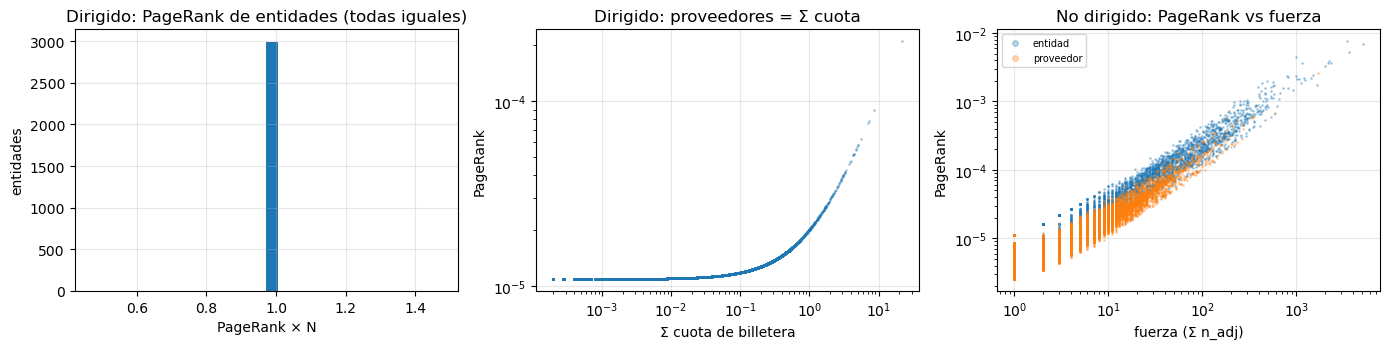

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].hist(r_dir[:n_e] * len(r_dir), bins=30)
ax[0].set(xlabel="PageRank × N", ylabel="entidades", title="Dirigido: PageRank de entidades (todas iguales)")
ax[1].loglog(cuota, r_dir[n_e:], ".", ms=2, alpha=.3)
ax[1].set(xlabel="Σ cuota de billetera", ylabel="PageRank", title="Dirigido: proveedores = Σ cuota")
for t, s_ in (("entidad", slice(0, n_e)), ("proveedor", slice(n_e, None))):
    ax[2].loglog(fuerza[s_], r_und[s_], ".", ms=2, alpha=.3, label=t)
ax[2].set(xlabel="fuerza (Σ n_adj)", ylabel="PageRank", title="No dirigido: PageRank vs fuerza"); ax[2].legend(fontsize=7, markerscale=4)
mostrar_fig("dirigido_vs_no_dirigido")

- **Dirigido:** las entidades quedan empatadas (rango relativo = 0) 

- El ranking de proveedores coincide al 100% con la suma de cuotas (Spearman = 1)

- Esa suma **sí es útil para PQ1**: mide dependencia, no centralidad, y se guarda como `cuota_billetera`

- **No dirigido:** correlacionado con la fuerza (Spearman 0.97 en entidades, 0.70 en proveedores)

| Variante | Entidades | Proveedores | Uso |
|---|---|---|---|
| Dirigido E → P | todas iguales | = Σ cuota de billetera | métrica de **dependencia** |
| **No dirigido E ↔ P** | recursivo | recursivo | **PageRank principal** |
| Bipartito E → P | hubs | authorities | **HITS** |

---
### **4. Peso de las aristas**

In [11]:
m_ = a.monto.fillna(0).to_numpy()
monto_nodo = np.r_[np.bincount(a.i, m_, n_e), np.bincount(a.j, m_, n_p)]
grado = np.asarray(M_bin.sum(axis=1)).ravel()
pr_peso = {p: pagerank_local(matriz_grafo(matriz_bip(a, n_e, n_p, p), False))[0] for p in RANGO_PESO}
P_ = slice(n_e, None)
eleccion = pd.DataFrame([{"peso": p, "spearman_grado": spearman(r[P_], grado[P_]), "spearman_monto": spearman(r[P_], monto_nodo[P_]),
                          "top20_vs_grado": top_jaccard(r[P_], grado[P_]), "top20_vs_monto": top_jaccard(r[P_], monto_nodo[P_]),
                          "spearman_vs_n_adj": spearman(r[P_], pr_peso["n_adj"][P_])} for p, r in pr_peso.items()]).round(3)
eleccion

,peso,spearman_grado,spearman_monto,top20_vs_grado,top20_vs_monto,spearman_vs_n_adj
0,binario,0.618,0.200,0.739,0.000,0.825
1,n_adj,0.564,0.263,0.481,0.026,1.000
2,log_monto,0.611,0.511,0.739,0.026,0.791
3,monto,0.306,0.856,0.333,0.176,0.358


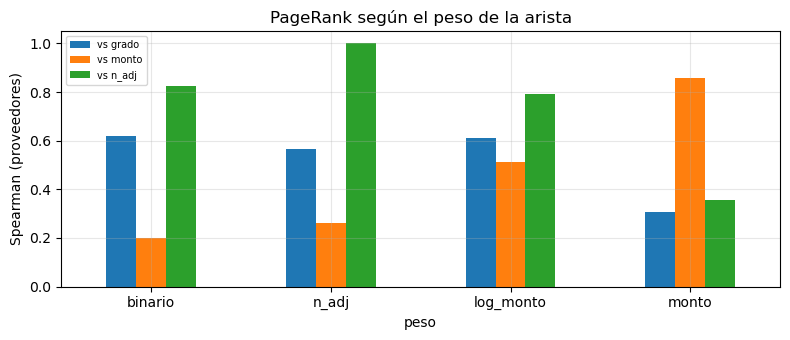

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.5))
e_ = eleccion.set_index("peso")[["spearman_grado", "spearman_monto", "spearman_vs_n_adj"]]
e_.columns = ["vs grado", "vs monto", "vs n_adj"]
e_.plot.bar(ax=ax, rot=0)
ax.set(ylabel="Spearman (proveedores)", title="PageRank según el peso de la arista"); ax.legend(fontsize=7)
mostrar_fig("eleccion_peso")

- **`monto`:** el PageRank copia el ranking de monto; megaobras dominan y no aporta frente a sumar montos

- **`binario`:** sigue al grado y trata igual una adjudicación que cien

- **`n_adj` (elegido):** mide la **recurrencia** de la relación, no su tamaño (Spearman con monto 0.26)

- Así el contraste centralidad vs monto es informativo

- **`log_monto`:** queda como robustez; su ranking coincide con `n_adj` en 0.79 (Spearman)


---
### **5. Exportación a `temp/datos/`**

- `nodos.parquet`: idx, tipo, nombre, componente, grado, fuerza (`n_adj`), monto y `cuota_billetera`

- `aristas.parquet`: índices enteros (i = entidad, j = proveedor) con `n_adj` y `monto`

In [13]:
v["clave"] = v.id.str[2:]
v["grado"], v["fuerza"], v["monto"] = grado.astype(int), fuerza, monto_nodo
v["cuota_billetera"] = np.r_[np.full(n_e, np.nan), cuota]
v.to_parquet(datos_dir / "nodos.parquet", index=False)
a[["i", "j", "n_adj", "monto", "anio_min", "anio_max", "en_gigante"]].to_parquet(datos_dir / "aristas.parquet", index=False)
guardar_config({"n_e": n_e, "n_p": n_p, "peso": PESO, "componentes": int(n_comp)})
print(f"temp/datos: nodos ({len(v):,}), aristas ({len(a):,}), config.json")

temp/datos: nodos (89,009), aristas (136,099), config.json


---
### **6. Escritura de resultados**

In [14]:
escritos = guardar_tablas({"resumen_grafo": resumen, "componentes": componentes, "dirigido_vs_no_dirigido": dirigido,
                           "eleccion_peso": eleccion,
                           "grado_bipartito": g.groupby(["tipo", "grado"]).size().reset_index(name="nodos")})

Escrito en 04_PageRank/temp/a_grafo/: resumen_grafo, componentes, dirigido_vs_no_dirigido, eleccion_peso, grado_bipartito


#### a. Verificación

In [15]:
verificar_salidas(escritos)
assert abs(r_und.sum() - 1) < 1e-9 and (r_und > 0).all(), "PageRank no es una distribución"
assert spearman(r_dir[n_e:], cuota) > 0.999, "la forma cerrada del dirigido no se cumple"
print("PageRank suma 1 | dirigido = Σ cuota de billetera")

OK: 5 tablas (parquet + json) | 4 figuras: ccdf_grado, componentes, dirigido_vs_no_dirigido, eleccion_peso
PageRank suma 1 | dirigido = Σ cuota de billetera


---
### **7. Cerrar sesión**

In [16]:
spark.stop()